# Generated Speech Set — EDA (Hindi, Tamil, Telugu)
### Unseen-generator test set for the real-vs-AI voice detector

**Milestone 2 — Group Project**

This notebook describes the fake speech that we generated ourselves with three open-source
text-to-speech models that are **not** used in IndicSynth:

| Generator | Type | Voices |
|---|---|---|
| **Indic Parler-TTS** (AI4Bharat) | Text-to-speech controlled by a text description of the voice | Recommended named speakers + unnamed male/female voices, 3 paces × 3 pitches |
| **IndicF5** (AI4Bharat) | Voice cloning from a reference recording | 10 IndicVoices-R speakers per language (5 female, 5 male) |
| **MMS-TTS** (Meta) | Single-voice VITS model | 1 voice per language |

For each language, 720 sentences were drawn (seed 42) from Kathbath's **test** split, leaving out
any sentence that also appears in Kathbath's train, valid or test_known split. Every sentence was
spoken by all three generators: **2,160 clips per language, 6,480 in total**. The clips were made with
`generate_fakes_kaggle.ipynb` on Kaggle (2 × T4) and stored as FLAC files with one JSON-lines manifest
row per clip in a private Hugging Face dataset.

**Contents**

0. Setup
1. Data checks
2. Overview
3. Input sentences
4. Voices
5. Duration and speaking rate
6. Loudness
7. IndicF5: pace of each reference voice
8. Listening examples
9. Conclusions and requirement checklist

## 0. Setup

The manifests (about 1 MB) are downloaded from the Hugging Face dataset. The dataset is private, so
a Hugging Face token with access is needed: from a Kaggle secret `HF_TOKEN`, the `HF_TOKEN`
environment variable or a saved `hf auth login`. Only the 9 clips played in section 8 are downloaded.

In [1]:
import csv
import glob
import json
import os
import warnings
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"  # keep download progress bars out of the outputs
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from huggingface_hub import hf_hub_download, snapshot_download
from IPython.display import Audio, Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

HF_REPO = "TarikaHedaoo/dsai-group3-fake-speech"
SENTENCES_FILE = Path("../../scratchpad/Tarika/milestone-2/sentences.csv")  # fixed sentence list (MD5 ad1f2223...)
SEED = 42

GENERATORS = ["indic-parler-tts", "indicf5", "mms-tts"]
GENERATOR_NAMES = {"indic-parler-tts": "Indic Parler-TTS", "indicf5": "IndicF5", "mms-tts": "MMS-TTS"}
LANGUAGES = ["hi", "ta", "te"]
LANGUAGE_NAMES = {"hi": "Hindi", "ta": "Tamil", "te": "Telugu"}

# One fixed hue per generator (checked for colour-blind separation).
COLORS = {"indic-parler-tts": "#2a78d6", "indicf5": "#eb6834", "mms-tts": "#1baf7a"}
GENDER_COLORS = {"f": "#2a78d6", "m": "#eb6834", "unknown": "#b4b2a9"}
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9})

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")  # None = use a saved `hf auth login`


def show_table(frame, caption):
    display(Markdown(f"**{caption}**"))
    display(frame)


def style_axes(ax, grid_axis="y"):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_MUTED)
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def box_by_generator(frame, column, ylabel, title):
    """One panel per language, one box per generator."""
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
    for ax, language in zip(axes, LANGUAGES):
        data = [frame[(frame.lang == language) & (frame.generator == g)][column].dropna() for g in GENERATORS]
        parts = ax.boxplot(data, widths=0.5, patch_artist=True,
                           medianprops={"color": INK, "linewidth": 1.5},
                           whiskerprops={"color": INK_MUTED}, capprops={"color": INK_MUTED},
                           flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": INK_MUTED,
                                       "markeredgecolor": "none", "alpha": 0.4})
        for box, generator in zip(parts["boxes"], GENERATORS):
            box.set_facecolor(COLORS[generator])
            box.set_edgecolor(SURFACE)
        ax.set_xticks(range(1, 4), [GENERATOR_NAMES[g] for g in GENERATORS], color=INK, fontsize=8.5)
        ax.set_title(LANGUAGE_NAMES[language], color=INK)
        style_axes(ax)
    axes[0].set_ylabel(ylabel, color=INK)
    fig.suptitle(title, color=INK, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

In [2]:
manifest_dir = snapshot_download(HF_REPO, repo_type="dataset", allow_patterns=["manifests/*"], token=HF_TOKEN)
rows = []
for path in sorted(glob.glob(f"{manifest_dir}/manifests/*/*/*.jsonl")):
    with open(path, encoding="utf-8") as f:
        rows += [json.loads(line) for line in f]
clips = pd.DataFrame(rows)
clips["n_words"] = clips["n_words"].astype(int)

with open(SENTENCES_FILE, encoding="utf-8") as f:
    sentences = pd.DataFrame(list(csv.DictReader(f)))
sentences["n_words"] = sentences["n_words"].astype(int)

print(f"{len(clips):,} manifest rows | {len(sentences):,} planned clips | columns: {', '.join(clips.columns)}")

6,480 manifest rows | 6,480 planned clips | columns: clip_id, sent_id, lang, generator, split, kb_file, kb_speaker, kb_gender, n_words, text, voice_id, voice_gender, description, duration_s, peak, rms, clipped_frac, flag_silent, flag_short, label, path, sha1, sample_rate, model_id, seed, gen_seconds, created_utc, error, ref_text


## 1. Data checks

Every planned clip should have exactly one manifest row and one audio file, and every manifest row
should agree with the fixed sentence list.

In [3]:
ok = clips[clips["error"].isna()]
expected, present = set(sentences.clip_id), set(clips.clip_id)
merged = clips.merge(sentences[["clip_id", "text", "lang", "generator", "sent_id"]], on="clip_id", suffixes=("", "_planned"))
mismatched = merged[(merged.text != merged.text_planned) | (merged.lang != merged.lang_planned)
                    | (merged.generator != merged.generator_planned) | (merged.sent_id != merged.sent_id_planned)]
generators_per_sentence = clips.groupby("sent_id").generator.nunique()


def check(name, value, passed, info=False):
    return {"check": name, "result": value, "status": "INFO" if info else ("PASS" if passed else "FAIL")}


checks = pd.DataFrame([
    check("Planned clips (sentence list)", f"{len(expected):,}", True, info=True),
    check("Manifest rows", f"{len(clips):,}", len(clips) == len(expected)),
    check("Missing clips", len(expected - present), not (expected - present)),
    check("Unexpected clips", len(present - expected), not (present - expected)),
    check("Duplicate clip IDs", int(clips.clip_id.duplicated().sum()), not clips.clip_id.duplicated().any()),
    check("Failed clips (no audio)", len(clips) - len(ok), len(ok) == len(clips)),
    check("Identical audio files (same SHA-1)", int(ok.sha1.duplicated().sum()), not ok.sha1.duplicated().any()),
    check("Empty values in key columns", int(ok[["clip_id", "text", "path", "sha1", "duration_s", "voice_id", "seed"]].isna().sum().sum()),
          ok[["clip_id", "text", "path", "sha1", "duration_s", "voice_id", "seed"]].notna().all().all()),
    check("Text / language / generator differ from the sentence list", len(mismatched), mismatched.empty),
    check("Sentences spoken by all 3 generators", f"{int((generators_per_sentence == 3).sum()):,} of {len(generators_per_sentence):,}",
          bool((generators_per_sentence == 3).all())),
    check("Sample rates", ", ".join(f"{GENERATOR_NAMES[g]}: {int(r):,} Hz" for g, r in clips.groupby("generator").sample_rate.first().items()),
          bool((clips.groupby("generator").sample_rate.nunique() == 1).all())),
    check("Labels / split", f"{', '.join(clips.label.unique())} / {', '.join(clips.split.unique())}",
          set(clips.label) == {"fake"} and set(clips.split) == {"test"}),
    check("Clips flagged silent", int(clips.flag_silent.sum()), True, info=True),
    check("Clips flagged shorter than 1 s", int(clips.flag_short.sum()), True, info=True),
    check("Clips with more than 1% clipped samples", int((clips.clipped_frac > 0.01).sum()), True, info=True),
])
show_table(checks, "Table 1.1 — Data checks (all clips)")
display(clips[clips.flag_silent | clips.flag_short][["clip_id", "voice_id", "duration_s", "rms", "text"]])

**Table 1.1 — Data checks (all clips)**

,check,result,status
0,Planned clips (sentence list),"6,480",INFO
1,Manifest rows,"6,480",PASS
2,Missing clips,0,PASS
3,Unexpected clips,0,PASS
4,Duplicate clip IDs,0,PASS
5,Failed clips (no audio),0,PASS
6,Identical audio files (same SHA-1),0,PASS
7,Empty values in key columns,0,PASS
8,Text / language / generator differ from the se...,0,PASS
9,Sentences spoken by all 3 generators,"2,160 of 2,160",PASS


,clip_id,voice_id,duration_s,rms,text
2051,te_0623_indic-parler-tts,parler-unnamed-m,6.65,0.00,ఎంఎల్ఏల ఫిరాయింపులపై ఏపి అసెంబ్లీ స్పీకర్ కోడె...


**Takeaway.** The set is complete: all 6,480 planned clips are present exactly once, none failed, no
two audio files are identical, and every clip's text, language and generator agree with the
sentence list. Every sentence is spoken by all three generators. One Parler clip (`te_0623`) is
almost silent (RMS 0.0002) and is flagged in its manifest, so preprocessing drops it. No clip is
shorter than 1 s or clipped.

## 2. Overview

In [4]:
overview = []
for generator in GENERATORS:
    for language in LANGUAGES:
        part = ok[(ok.generator == generator) & (ok.lang == language)]
        overview.append({
            "generator": GENERATOR_NAMES[generator], "language": LANGUAGE_NAMES[language], "clips": len(part),
            "hours": part.duration_s.sum() / 3600, "duration_median_s": part.duration_s.median(),
            "duration_min_s": part.duration_s.min(), "duration_max_s": part.duration_s.max(),
            "sample_rate": int(part.sample_rate.iloc[0]), "voices": part.voice_id.nunique(),
            "mean_gen_seconds": part.gen_seconds.mean(),
        })
overview = pd.DataFrame(overview)
show_table(overview, "Table 2.1 — Clips, hours and durations per generator and language")
print(f"Total: {len(ok):,} clips, {ok.duration_s.sum() / 3600:.2f} hours")

**Table 2.1 — Clips, hours and durations per generator and language**

,generator,language,clips,hours,duration_median_s,duration_min_s,duration_max_s,sample_rate,voices,mean_gen_seconds
0,Indic Parler-TTS,Hindi,720,0.99,4.79,2.19,10.23,44100,4,14.48
1,Indic Parler-TTS,Tamil,720,1.41,6.77,3.34,15.51,44100,3,21.77
2,Indic Parler-TTS,Telugu,720,1.37,6.57,3.40,14.36,44100,4,20.68
3,IndicF5,Hindi,720,1.04,5.00,1.92,10.32,24000,10,11.48
4,IndicF5,Tamil,720,0.98,4.62,1.98,10.82,24000,10,10.79
5,IndicF5,Telugu,720,1.36,6.37,2.82,19.38,24000,10,13.34
6,MMS-TTS,Hindi,720,0.98,4.85,2.66,8.59,16000,1,0.13
7,MMS-TTS,Tamil,720,1.61,7.87,3.95,17.31,16000,1,0.19
8,MMS-TTS,Telugu,720,1.52,7.36,4.05,13.73,16000,1,0.18


Total: 6,480 clips, 11.25 hours


**Takeaway.** Each generator contributes 2,160 clips (720 per language); together they hold
**11.25 hours** of speech. The generators keep their native sample rates (Parler 44.1 kHz, IndicF5
24 kHz, MMS-TTS 16 kHz); resampling to 16 kHz happens in the shared preprocessing step. Generation
cost differs widely: MMS-TTS needs well under a second per clip, IndicF5 about 12 s and Parler
about 19 s on a T4.

## 3. Input sentences

**Table 3.1 — The 720 sentences per language**

,sentences,kathbath_speakers,words_min,words_median,words_max,female_reader_share
lang,,,,,,
Hindi,720,20,8,12.00,16,0.50
Tamil,720,20,6,10.00,15,0.57
Telugu,720,20,8,10.00,15,0.51


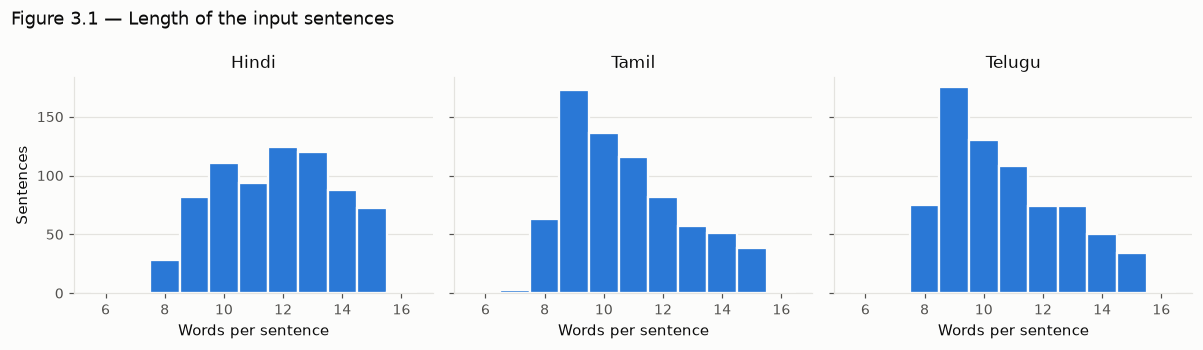

In [5]:
one = sentences.drop_duplicates("sent_id")
sentence_stats = one.groupby("lang").agg(
    sentences=("sent_id", "size"), kathbath_speakers=("kb_speaker", "nunique"),
    words_min=("n_words", "min"), words_median=("n_words", "median"), words_max=("n_words", "max"),
    female_reader_share=("kb_gender", lambda g: (g == "f").mean()))
sentence_stats.index = sentence_stats.index.map(LANGUAGE_NAMES)
show_table(sentence_stats, "Table 3.1 — The 720 sentences per language")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
bins = np.arange(one.n_words.min() - 0.5, one.n_words.max() + 1.5)
for ax, language in zip(axes, LANGUAGES):
    ax.hist(one[one.lang == language].n_words, bins=bins, color=COLORS["indic-parler-tts"], edgecolor=SURFACE, linewidth=1.5)
    ax.set_title(LANGUAGE_NAMES[language], color=INK)
    ax.set_xlabel("Words per sentence", color=INK)
    ax.set_xticks(range(one.n_words.min(), one.n_words.max() + 1, 2))
    style_axes(ax)
axes[0].set_ylabel("Sentences", color=INK)
fig.suptitle("Figure 3.1 — Length of the input sentences", color=INK, x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Takeaway.** The sentences come from all 20 Kathbath test speakers of each language, about half of
them read by women, and are 6–16 words long (most 8–15). Hindi sentences are slightly longer than
Tamil and Telugu ones in words, but Tamil and Telugu words are longer, so the spoken durations end
up similar or longer (section 5).

## 4. Voices

**Table 4.1 — Clips by voice gender**

voice_gender               f    m  unknown
generator        lang                     
Indic Parler-TTS Hindi   360  360        0
                 Tamil   480  240        0
                 Telugu  360  360        0
IndicF5          Hindi   360  360        0
                 Tamil   360  360        0
                 Telugu  360  360        0
MMS-TTS          Hindi     0    0      720
                 Tamil     0    0      720
                 Telugu    0    0      720

**Table 4.2 — Parler and MMS-TTS voices**

,generator,lang,voice_id,voice_gender,clips
0,Indic Parler-TTS,Hindi,parler-divya,f,180
1,Indic Parler-TTS,Hindi,parler-rohit,m,180
2,Indic Parler-TTS,Hindi,parler-unnamed-f,f,180
3,Indic Parler-TTS,Hindi,parler-unnamed-m,m,180
4,Indic Parler-TTS,Tamil,parler-jaya,f,240
5,Indic Parler-TTS,Tamil,parler-unnamed-f,f,240
6,Indic Parler-TTS,Tamil,parler-unnamed-m,m,240
7,Indic Parler-TTS,Telugu,parler-lalitha,f,180
8,Indic Parler-TTS,Telugu,parler-prakash,m,180
9,Indic Parler-TTS,Telugu,parler-unnamed-f,f,180


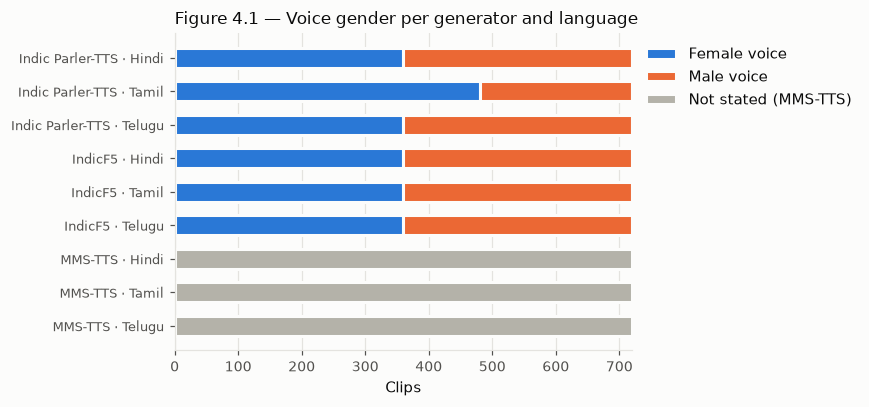

In [6]:
voices = (ok.groupby(["generator", "lang", "voice_id", "voice_gender"]).size().rename("clips").reset_index())
voices["generator"] = voices.generator.map(GENERATOR_NAMES)
voices["lang"] = voices.lang.map(LANGUAGE_NAMES)
show_table(voices.pivot_table(index=["generator", "lang"], columns="voice_gender", values="clips", aggfunc="sum", fill_value=0),
           "Table 4.1 — Clips by voice gender")
show_table(voices[voices.generator != "IndicF5"], "Table 4.2 — Parler and MMS-TTS voices")

fig, ax = plt.subplots(figsize=(8, 3.8))
labels, counts = [], {"f": [], "m": [], "unknown": []}
for generator in GENERATORS:
    for language in LANGUAGES:
        part = ok[(ok.generator == generator) & (ok.lang == language)]
        labels.append(f"{GENERATOR_NAMES[generator]} · {LANGUAGE_NAMES[language]}")
        for gender in counts:
            counts[gender].append((part.voice_gender == gender).sum())
y, left = np.arange(len(labels))[::-1], np.zeros(len(labels))
names = {"f": "Female voice", "m": "Male voice", "unknown": "Not stated (MMS-TTS)"}
for gender, values in counts.items():
    ax.barh(y, values, height=0.6, left=left, color=GENDER_COLORS[gender], label=names[gender], edgecolor=SURFACE, linewidth=2)
    left += np.array(values)
ax.set_yticks(y, labels, color=INK, fontsize=8.5)
ax.set_xlabel("Clips", color=INK)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), labelcolor=INK)
ax.set_title("Figure 4.1 — Voice gender per generator and language", color=INK, loc="left")
style_axes(ax, grid_axis="x")
fig.tight_layout()
plt.show()

**Takeaway.** IndicF5 is exactly balanced (5 female and 5 male cloned voices per language, 72 clips
each). Parler is balanced for Hindi and Telugu, but **Tamil is 2:1 female**, because the model card
recommends only one Tamil speaker (Jaya, female). MMS-TTS has a single voice per language whose
gender is not stated by its authors. Per-gender results later must therefore use Parler and IndicF5
only, and weight Tamil accordingly.

## 5. Duration and speaking rate

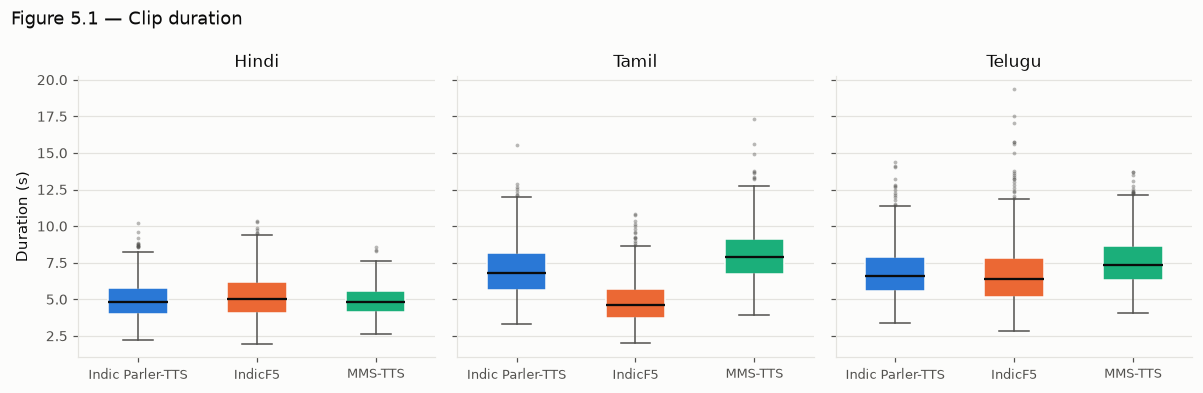

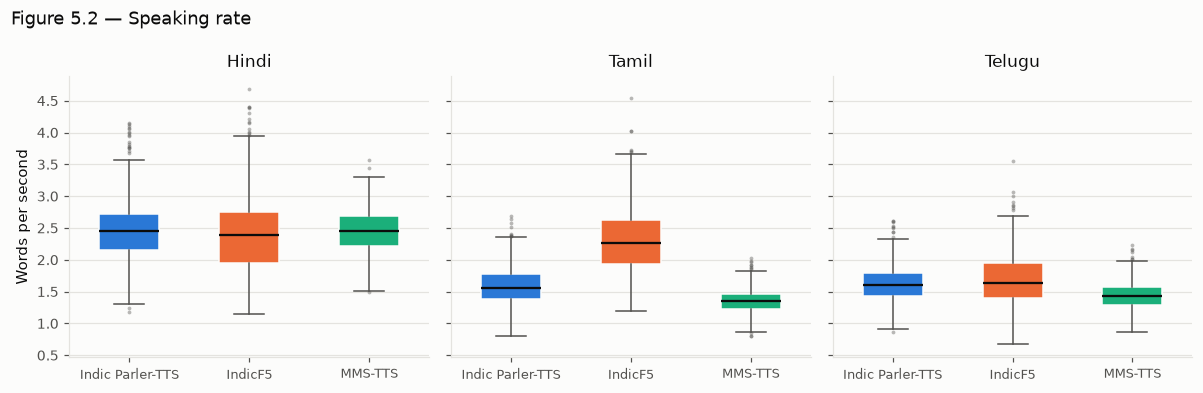

**Table 5.1 — Median words per second**

lang,Hindi,Tamil,Telugu
generator,,,
Indic Parler-TTS,2.46,1.56,1.61
IndicF5,2.39,2.27,1.64
MMS-TTS,2.45,1.35,1.43


In [7]:
ok = ok.assign(words_per_s=ok.n_words / ok.duration_s)
box_by_generator(ok, "duration_s", "Duration (s)", "Figure 5.1 — Clip duration")
box_by_generator(ok, "words_per_s", "Words per second", "Figure 5.2 — Speaking rate")
show_table(ok.pivot_table(index="generator", columns="lang", values="words_per_s", aggfunc="median")
           .rename(index=GENERATOR_NAMES, columns=LANGUAGE_NAMES), "Table 5.1 — Median words per second")

**Takeaway.** The same sentences take different lengths with different generators. In Hindi all three
speak at about 2.4 words per second. In Tamil and Telugu, Parler and MMS-TTS are slower (about
1.3–1.7 words per second), while IndicF5 Tamil is faster (about 2.3), because it copies the fast
conversational style of its reference recordings. Clip length therefore depends on the generator,
which is one reason why training uses fixed-length crops rather than whole clips.

## 6. Loudness

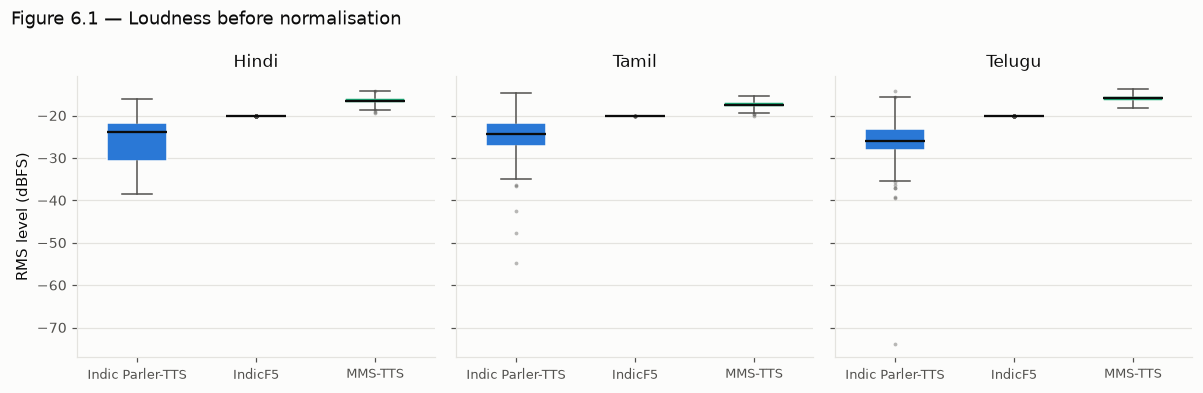

**Table 6.1 — Median RMS level (dBFS)**

lang,Hindi,Tamil,Telugu
generator,,,
Indic Parler-TTS,-23.94,-24.26,-25.90
IndicF5,-20.00,-20.00,-20.00
MMS-TTS,-16.53,-17.45,-15.95


In [8]:
ok = ok.assign(rms_dbfs=20 * np.log10(ok.rms.clip(lower=1e-6)))
box_by_generator(ok, "rms_dbfs", "RMS level (dBFS)", "Figure 6.1 — Loudness before normalisation")
show_table(ok.pivot_table(index="generator", columns="lang", values="rms_dbfs", aggfunc="median")
           .rename(index=GENERATOR_NAMES, columns=LANGUAGE_NAMES), "Table 6.1 — Median RMS level (dBFS)")

**Takeaway.** Loudness separates the generators almost perfectly: IndicF5 normalises every clip to
exactly −20 dBFS inside its own code, MMS-TTS sits around −16 to −17 dBFS, and Parler is quieter and
more variable (median −24 to −26 dBFS). A detector could recognise IndicF5 by its constant level
alone, so every clip, real or fake, is loudness-normalised in preprocessing.

## 7. IndicF5: pace of each reference voice

IndicF5 imitates the speaking pace of its reference recording. To check that no reference voice
makes the clips unnaturally slow or fast, each IndicF5 clip is compared with the Parler clip of the
**same sentence**: a ratio of 1 means the same length.

In [9]:
parler_duration = ok[ok.generator == "indic-parler-tts"].set_index("sent_id").duration_s
f5 = ok[ok.generator == "indicf5"].copy()
f5["ratio_to_parler"] = f5.duration_s / f5.sent_id.map(parler_duration)
pace = (f5.groupby(["lang", "voice_id", "voice_gender"])
        .agg(clips=("clip_id", "size"), median_ratio_to_parler=("ratio_to_parler", "median"),
             reference_text=("ref_text", "first"))
        .reset_index().sort_values(["lang", "median_ratio_to_parler"]))
pace["lang"] = pace.lang.map(LANGUAGE_NAMES)
pace["reference_text"] = pace.reference_text.str.slice(0, 45)
show_table(pace, "Table 7.1 — IndicF5 clip length relative to Parler, per reference voice")

**Table 7.1 — IndicF5 clip length relative to Parler, per reference voice**

,lang,voice_id,voice_gender,clips,median_ratio_to_parler,reference_text
3,Hindi,ivr-S4257196900365559,m,72,0.68,क्योंकि इससे मैंने अनेक सी चीज़ें मुझे इससे जा
8,Hindi,ivr-S4258561600395718,f,72,0.90,और जो सुबह दस बजे से पहले का समय है वे हमारो
6,Hindi,ivr-S4258388600389373,m,72,0.93,हमारे यहाँ के क्षेत्र में चम्बल संभाग में यहा
0,Hindi,ivr-S4256820200338001,f,72,0.95,इसके अलावा कई सारी ऐसे पत्रिकाएँ भी समाचार पत
4,Hindi,ivr-S4257878300397507,f,72,0.99,मेरे अनुसार जीवन का हर पल का आनंद लेने के अवध
7,Hindi,ivr-S4258486700370849,m,72,1.06,बिजनिस को तैयार कर के लोग अपने और को अग्रेषित
1,Hindi,ivr-S4256942400332561,f,72,1.08,नमस्ते भैया हम ने आपका कैब बुक किया था ओला से
9,Hindi,ivr-S4258858600387188,m,72,1.18,प्रतिभा विकास किया तो वो इंटरनेशनल तक खेल खेल
5,Hindi,ivr-S4258354000329548,m,72,1.43,तो योगासन करने से हमें काफ़ी हद तक
2,Hindi,ivr-S4257120600367211,f,72,1.46,प्रियदर्शनी हैं जो देखने लायक है और वहाँ पे


**Takeaway.** Per reference voice, IndicF5 clips are 0.55–1.57 times as long as Parler's clip of the
same sentence. The fastest voices are Tamil speakers whose references are rapid conversational
speech; the slowest is one Telugu voice (about 1.6×) with a hesitant reference. This is natural
variation in speaking rate, not a failure: every reference transcript has at least 8 words, which
removed the slowly read lists of names and numbers that had produced clips at under 1 word per
second during testing.

## 8. Listening examples

The first sentence of each language, spoken by all three generators (9 clips are downloaded).

In [10]:
for language in LANGUAGES:
    sent_id = f"{language}_0001"
    display(Markdown(f"**{LANGUAGE_NAMES[language]}** — {sentences[sentences.sent_id == sent_id].text.iloc[0]}"))
    for generator in GENERATORS:
        row = ok[(ok.sent_id == sent_id) & (ok.generator == generator)].iloc[0]
        path = hf_hub_download(HF_REPO, row.path, repo_type="dataset", token=HF_TOKEN)
        audio, sr = sf.read(path)
        print(f"{GENERATOR_NAMES[generator]:17} {row.voice_id:30} {row.duration_s:5.2f} s")
        display(Audio(audio, rate=sr))

**Hindi** — डियोड्रेंट में कई तरह के सिंथेटिक और रसायन मौजूद होते हैं

Indic Parler-TTS  parler-rohit                    4.93 s


IndicF5           ivr-S4257196900365559           3.38 s


MMS-TTS           mms-hi                          5.07 s


**Tamil** — இதேவேளை உபாதைக் குள்ளாகியிருக்கும் வேகப்பந்து வீச்சாளர் சுரங்க லக்மாலும் இக் குழாமில் பெயரிடப்பட்டுள்ளார்

...

MMS-TTS           mms-ta                          8.75 s


**Telugu** — ఈ ప్రాంతంలో ప్రజాజీవితంలో దనసరి అవసరాలకు అనుగుణంగా మారుతూ వస్తుంది

Indic Parler-TTS  parler-prakash                  5.10 s


IndicF5           ivr-S4256002300334350           8.48 s


MMS-TTS           mms-te                          7.49 s


## 9. Conclusions and requirement checklist

In [11]:
checklist = pd.DataFrame([
    ("Details of the generation process", "intro, 2", "Generators, sentence selection, 720 × 3 × 3 design; Table 2.1"),
    ("Design choices explained", "intro, 4, 7", "Parallel sentences, voice choices (Tables 4.1, 7.1)"),
    ("Dataset size and characteristics", "2–6", "Tables 2.1, 3.1, 5.1, 6.1; Figures 3.1–6.1"),
    ("Missing, inconsistent and duplicate data", "1", "Table 1.1"),
    ("Audio quality", "1, 5, 6", "Silence/short/clipping flags; duration and loudness per generator"),
    ("Transcription alignment", "1, 7, 8", "Text matches the sentence list; pace check; listening examples"),
    ("Sampling consistency", "1, 2", "One sample rate per generator, resampled to 16 kHz in preprocessing"),
    ("Reproducibility", "0", "Fixed sentence list (seed 42), fixed seed per clip, pinned manifests"),
], columns=["requirement", "section", "evidence"])
show_table(checklist, "Table 9.1 — Milestone-2 requirements covered by this notebook")

**Table 9.1 — Milestone-2 requirements covered by this notebook**

,requirement,section,evidence
0,Details of the generation process,"intro, 2","Generators, sentence selection, 720 × 3 × 3 de..."
1,Design choices explained,"intro, 4, 7","Parallel sentences, voice choices (Tables 4.1,..."
2,Dataset size and characteristics,2–6,"Tables 2.1, 3.1, 5.1, 6.1; Figures 3.1–6.1"
3,"Missing, inconsistent and duplicate data",1,Table 1.1
4,Audio quality,"1, 5, 6",Silence/short/clipping flags; duration and lou...
5,Transcription alignment,"1, 7, 8",Text matches the sentence list; pace check; li...
6,Sampling consistency,"1, 2","One sample rate per generator, resampled to 16..."
7,Reproducibility,0,"Fixed sentence list (seed 42), fixed seed per ..."


**Final conclusion.** The generated set is complete and consistent: 6,480 clips (11.25 hours), 720
sentences per language each spoken by three generators that IndicSynth does not use, with no failed,
duplicate or clipped clips and one silent clip flagged. It is suitable as the **unseen-generator
test set**: its sentences come from Kathbath's test speakers only, so it pairs with their real
recordings and shares no text with the training data. Three properties are handled outside the
data itself: loudness and duration differ by generator (removed by loudness normalisation and
fixed-length crops), and Parler's Tamil voices are mostly female (reported per gender).